Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        f

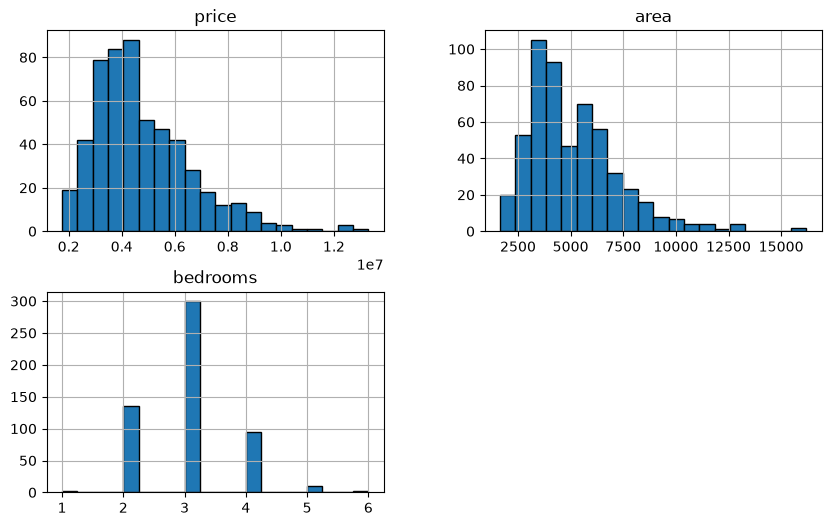

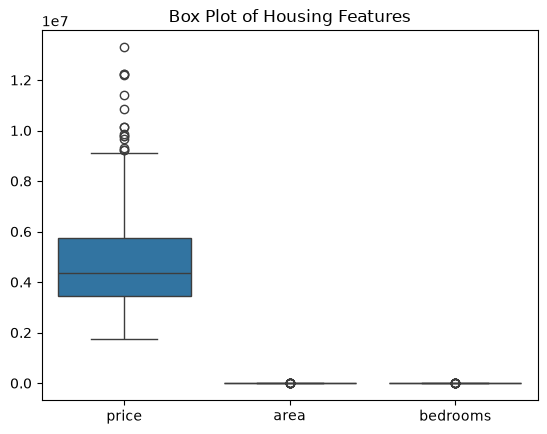


Correlation Matrix:
             price      area  bedrooms
price     1.000000  0.535997  0.366494
area      0.535997  1.000000  0.151858
bedrooms  0.366494  0.151858  1.000000


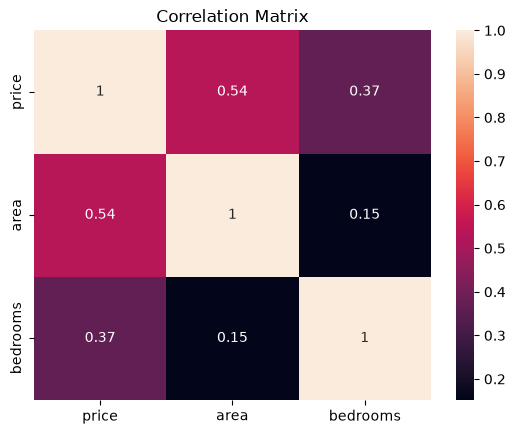


Covariance Matrix:
                 price          area       bedrooms
price     3.498544e+12  2.175676e+09  505946.425931
area      2.175676e+09  4.709512e+06     243.232140
bedrooms  5.059464e+05  2.432321e+02       0.544738

Price and Area:
Correlation: 0.5359973457780801
Covariance: 2175676334.874865

Pivot Table:
                  mean     median count
                 price      price price
bedrooms                               
1         2.712500e+06  2712500.0     2
2         3.632022e+06  3535000.0   136
3         4.954598e+06  4620000.0   300
4         5.729758e+06  5250000.0    95
5         5.819800e+06  5582500.0    10
6         4.791500e+06  4791500.0     2


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv(r"A:\Collge Code\Housing.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Check column names
print("Columns:", df.columns.tolist())

# Inspect dataset
print(df.head())
print(df.info())
print("Shape:", df.shape)
print("Missing Values:\n", df.isnull().sum())


# b. Summary statistics
for col in ['price', 'area', 'bedrooms']:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())


# c. Histograms
df[['price', 'area', 'bedrooms']].hist(
    bins=20, figsize=(10, 6), edgecolor='black'
)
plt.show()


# c. Box plots
sns.boxplot(data=df[['price', 'area', 'bedrooms']])
plt.title("Box Plot of Housing Features")
plt.show()


# d. Correlation analysis
corr = df[['price', 'area', 'bedrooms']].corr()
print("\nCorrelation Matrix:")
print(corr)

sns.heatmap(corr, annot=True)
plt.title("Correlation Matrix")
plt.show()


# d. Covariance analysis
cov = df[['price', 'area', 'bedrooms']].cov()
print("\nCovariance Matrix:")
print(cov)


# e. Price and Area relationship
print("\nPrice and Area:")
print("Correlation:", df['price'].corr(df['area']))
print("Covariance:", df['price'].cov(df['area']))


# f. Pivot table
pivot = pd.pivot_table(
    df,
    values='price',
    index='bedrooms',
    aggfunc=['mean', 'median', 'count']
)

print("\nPivot Table:")
print(pivot)